# 04_1 — BTV0125 images: PCA

Instead of hand-made beam parameters (notebook 04), let PCA find the main ways the images change from shot to shot,
then check which of those patterns follow the charge (`BCM_GUN`).

1. **Preprocess** each image like notebook 04: crop the ROI, subtract the background, 3×3 median filter (hot pixels),
   then **bin 4×4** → 200 × 212 pixels (0.043 mm/pixel; the beam σ is ~0.29 mm, so it is still well resolved).
   The stack is cached in `outputs/` so this runs only once (~2–3 min).
2. **PCA** on the mean-subtracted images → the first 6 components (eigen-images) and each shot's score on them.
3. **Correlate** the 6 scores with `BCM_GUN`. The camera and BCM_GUN are stored in the same row, so no shift is needed.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import ndimage

DATA_DIR = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
OUT_DIR = DATA_DIR.parent / "outputs"
OUT_DIR.mkdir(exist_ok=True)
files = sorted(DATA_DIR.glob("chunk_*.h5"))

ROI = (slice(350, 1150), slice(600, 1450))  # same as notebook 04
BG_ROWS = slice(0, 150)
BIN = 4
N_COMPONENTS = 10

DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
POINT, INK = "#2a78d6", "#2b2b29"

## 1. Preprocess and cache

In [2]:
def preprocess(raw):
    raw = raw.astype(np.float32)
    img = ndimage.median_filter(raw[ROI], size=3) - np.median(raw[BG_ROWS])
    h, w = (s // BIN * BIN for s in img.shape)
    return img[:h, :w].reshape(h // BIN, BIN, w // BIN, BIN).mean(axis=(1, 3))


cache = OUT_DIR / f"btv0125_roi_bin{BIN}.npz"
if cache.exists():
    stored = np.load(cache)
    images, image_number = stored["images"], stored["image_number"]
else:
    images, image_number = [], []
    for path in files:
        with h5py.File(path, "r") as f:
            btv = f["BTV0125"]
            image_number.append(btv["imageNumber"][:])
            images += [preprocess(btv["image2D"][i]) for i in range(btv["image2D"].shape[0])]
    images, image_number = np.stack(images), np.concatenate(image_number)
    np.savez(cache, images=images, image_number=image_number)

bcm_gun = np.concatenate([h5py.File(path, "r")["BCM_GUN"][:] for path in files])
frozen = np.r_[False, np.diff(image_number) == 0]
print(f"images {images.shape}, frozen camera shots: {frozen.sum()}")

images (2100, 200, 212), frozen camera shots: 1


## 2. PCA

In [3]:
keep = ~frozen
X = images[keep].reshape(keep.sum(), -1)
mean_image = X.mean(axis=0)
Xc = X - mean_image

# SVD of the (shots × pixels) matrix: rows of Vt are the eigen-images, U·S are the per-shot scores
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
explained = S**2 / np.sum(S**2)
scores = pd.DataFrame(U[:, :N_COMPONENTS] * S[:N_COMPONENTS], columns=[f"PC{k + 1}" for k in range(N_COMPONENTS)])
eigen_images = Vt[:N_COMPONENTS].reshape(N_COMPONENTS, *images.shape[1:])

for k in range(N_COMPONENTS):
    print(f"PC{k + 1}: {explained[k]:6.1%} of the variance (cumulative {explained[:k + 1].sum():.1%})")

PC1:  39.9% of the variance (cumulative 39.9%)
PC2:  29.9% of the variance (cumulative 69.8%)
PC3:   9.9% of the variance (cumulative 79.7%)
PC4:   3.8% of the variance (cumulative 83.5%)
PC5:   1.8% of the variance (cumulative 85.3%)
PC6:   1.0% of the variance (cumulative 86.3%)
PC7:   0.9% of the variance (cumulative 87.2%)
PC8:   0.5% of the variance (cumulative 87.8%)
PC9:   0.4% of the variance (cumulative 88.2%)
PC10:   0.3% of the variance (cumulative 88.5%)


In [4]:
# save the scores, one row per shot (NaN for the frozen camera shot) — used by notebook 05
scores_all = pd.DataFrame(np.nan, index=pd.RangeIndex(len(images), name="shot"), columns=scores.columns)
scores_all.loc[keep] = scores.to_numpy()
scores_all.to_csv(OUT_DIR / "btv0125_pca_scores.csv")
print(f"saved {OUT_DIR / 'btv0125_pca_scores.csv'}")

saved /Users/angilard/Desktop/Fast-Approximate/outputs/btv0125_pca_scores.csv


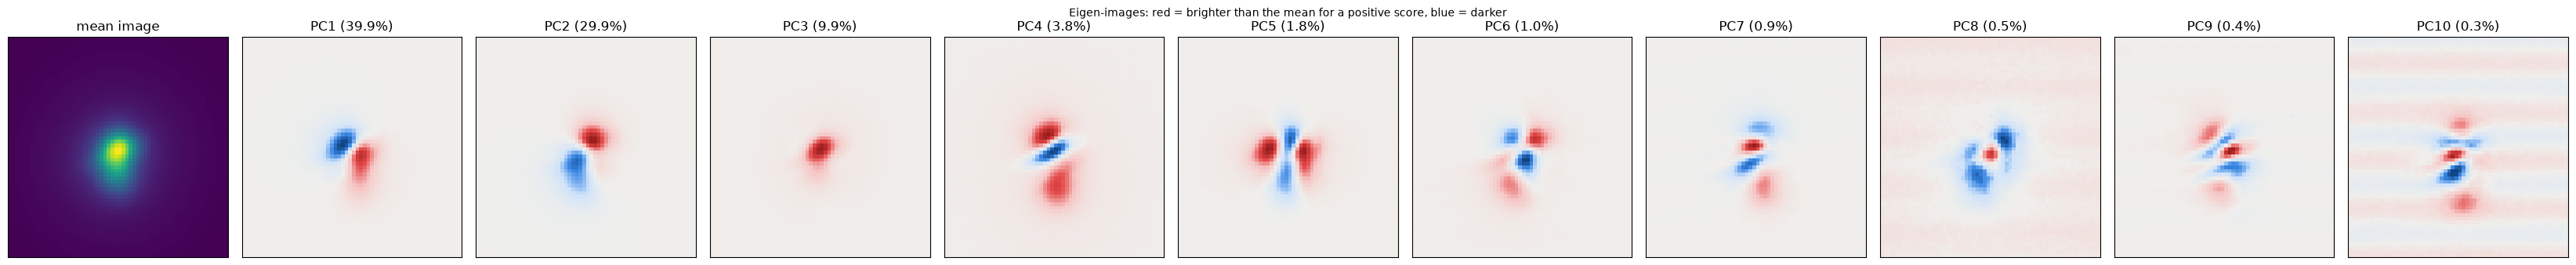

In [5]:
# zoom the display on the beam: ±30 binned pixels (±1.3 mm) around the peak of the mean image
shape = images.shape[1:]
cy, cx = np.unravel_index(mean_image.argmax(), shape)
zoom = (slice(cy - 30, cy + 30), slice(cx - 30, cx + 30))

fig, axes = plt.subplots(1, N_COMPONENTS + 1, figsize=(3 * (N_COMPONENTS + 1), 3.4))
axes[0].imshow(mean_image.reshape(shape)[zoom], cmap="viridis")
axes[0].set_title("mean image")
for k, ax in enumerate(axes[1:]):
    lim = np.abs(eigen_images[k]).max()
    ax.imshow(eigen_images[k][zoom], cmap=DIVERGING, vmin=-lim, vmax=lim)
    ax.set_title(f"PC{k + 1} ({explained[k]:.1%})")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Eigen-images: red = brighter than the mean for a positive score, blue = darker", fontsize=10)
fig.tight_layout()

### What does each component look like in the classic parameters?

Correlation of each PC score with the beam parameters from notebook 04 (`outputs/btv0125_params.csv`) — helps to name the components.

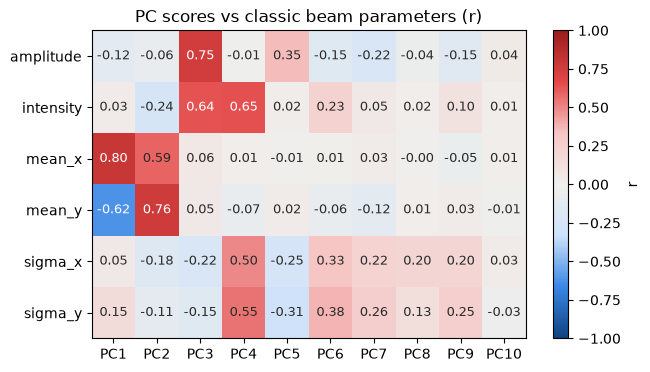

In [6]:
classic = pd.read_csv(OUT_DIR / "btv0125_params.csv", index_col="shot")[keep]
classic_cols = ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]
naming = pd.DataFrame({pc: [np.corrcoef(scores[pc], classic[c])[0, 1] for c in classic_cols] for pc in scores}, index=classic_cols)

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(naming, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(naming.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(r) > 0.6 else INK)
ax.set_xticks(range(N_COMPONENTS), naming.columns)
ax.set_yticks(range(len(classic_cols)), classic_cols)
ax.set_title("PC scores vs classic beam parameters (r)")
fig.colorbar(im, ax=ax, label="r");

## 3. PC scores vs charge

**Overall** r includes the slow drift over the run; **shot-to-shot** r removes it (51-shot rolling mean).

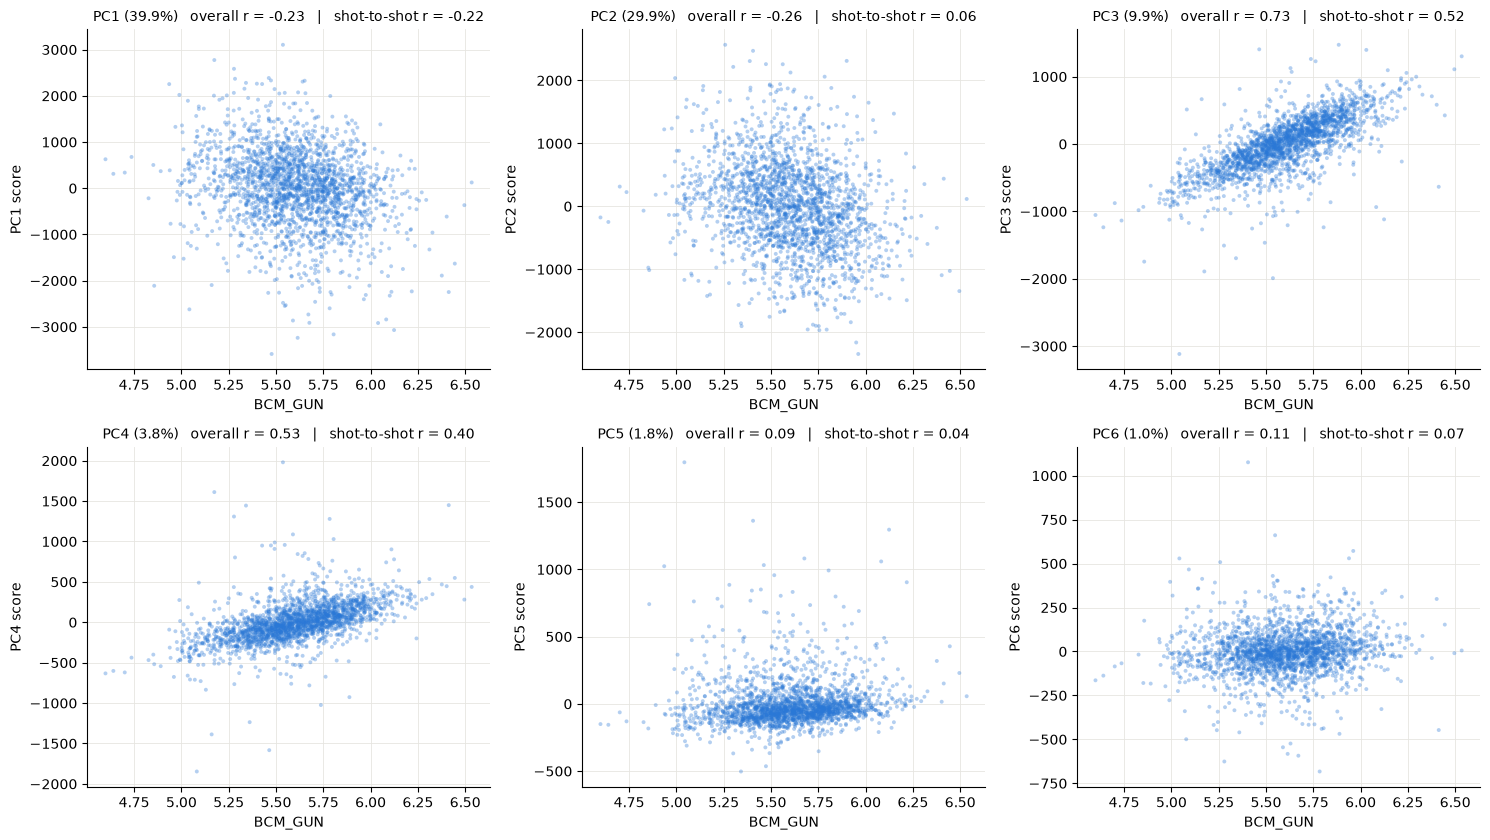

In [7]:
charge = pd.Series(bcm_gun[keep])


def detrend(x, k=51):
    return x - x.rolling(k, center=True, min_periods=1).mean()


fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, pc in zip(axes.ravel(), scores.columns):
    r_all = scores[pc].corr(charge)
    r_fast = detrend(scores[pc]).corr(detrend(charge))
    ax.scatter(charge, scores[pc], s=8, color=POINT, alpha=0.35, edgecolors="none")
    ax.set(xlabel="BCM_GUN", ylabel=f"{pc} score",
           title=f"{pc} ({explained[int(pc[2:]) - 1]:.1%})   overall r = {r_all:.2f}   |   shot-to-shot r = {r_fast:.2f}")
    ax.title.set_fontsize(10)
    ax.grid(color="#e6e5e1", lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
fig.tight_layout()